![Banner](../images/09_06_banner_rs_lidar.png)


# Terrain and Hydrology from LiDAR DEMs

A LiDAR bare-earth DEM shows terrain in metre-scale detail: stream channels, terraces, road embankments, ditches and gullies that coarser elevation models smooth away. This notebook builds a 1 m DEM of the Six Mile Creek valley in Ithaca, New York, from four USGS 3DEP tiles and derives the standard terrain variables (slope, aspect, curvature, topographic position, ruggedness, landforms) and hydrological layers (depression filling, flow direction and accumulation, stream networks, wetness index, height above nearest drainage and flood extent) with `geolattice.rsense.lidar`.


## Overview

Terrain variables describe the shape of the land surface and are inputs to hydrology, soil, geomorphology, habitat and hazard models. They fall into two groups:

- **Local derivatives** use only a small neighbourhood (usually 3 x 3 cells): slope, aspect, curvature, ruggedness and hillshade. They can be computed independently for every cell, so they parallelise well and run on a GPU.
- **Regional or flow-based variables** depend on the whole upstream area: flow accumulation, wetness index, height above drainage. They need a sequential routing algorithm over the entire DEM.

LiDAR DEMs bring their own challenges. At 1 m, bridges and road embankments without culverts act as dams in the DEM, water surfaces are noisy or empty because water absorbs the laser, and small artefacts create spurious pits. Hydrological work therefore usually **conditions** the DEM first: flattening water bodies, burning or breaching culverts and filling depressions.


### Local terrain derivatives

Let $z_{a}, \dots, z_{i}$ be the 3 x 3 neighbourhood of a cell (row-major from the top-left, $z_e$ in the centre) with cell size $\Delta x$, $\Delta y$. **Horn's (1981)** gradient weights the centre row and column twice:

$$\frac{\partial z}{\partial x} = \frac{(z_c + 2z_f + z_i) - (z_a + 2z_d + z_g)}{8\,\Delta x}, \qquad \frac{\partial z}{\partial y} = \frac{(z_g + 2z_h + z_i) - (z_a + 2z_b + z_c)}{8\,\Delta y}.$$

| Variable | Definition | Meaning |
|---|---|---|
| Slope | $\arctan\sqrt{(\partial z/\partial x)^2 + (\partial z/\partial y)^2}$ | Steepness; controls runoff speed, erosion and landslide risk |
| Aspect | Compass direction of steepest descent | Exposure to sun and wind; snow melt, vegetation |
| Curvature | Laplacian $\nabla^2 z$ | Convex (ridges, negative here) versus concave (hollows, positive here); flow divergence and convergence |
| TPI | $z - \bar z_{\text{window}}$ | Topographic Position Index: positive on ridges and hilltops, negative in valleys; depends on the window size |
| TRI | $\sqrt{\sum (z_j - z_e)^2}$ over the 8 neighbours | Terrain Ruggedness Index (Riley et al. 1999) |
| Roughness | $\max - \min$ in the 3 x 3 window | Local relief |
| Hillshade | $255\,(\cos Z \cos \theta + \sin Z \sin \theta \cos(A - \phi))$ | Shaded relief for a sun at zenith angle $Z$ and azimuth $A$, for slope $\theta$ and aspect $\phi$ |
| Illumination | $\cos i$, the same expression without scaling | Used for the topographic correction of optical images |

**Geomorphons** (Jasiewicz and Stepinski 2013) classify landforms by looking along eight directions from each cell up to a search distance and recording whether the horizon is higher, lower or level. The pattern of "higher" and "lower" directions maps to ten landforms: flat, peak, ridge, shoulder, spur, slope, hollow, footslope, valley and pit. Unlike curvature, geomorphons adapt to the scale of the landform through the search distance.


### Hydrological derivatives

1. **Depression filling.** Pits in the DEM trap flow. The **priority-flood** algorithm (Barnes et al. 2014) floods the DEM inwards from its edges, always continuing from the lowest cell on the boundary of the flooded region, and raises every pit to its spill level. A tiny gradient ($\epsilon$) on filled flats keeps water moving.
2. **Flow direction (D8).** Each cell drains to the one of its eight neighbours with the steepest downward slope (O'Callaghan and Mark 1984).
3. **Flow accumulation.** The number of cells (or the area) draining through each cell. Cells above a threshold form the **stream network**.
4. **Topographic Wetness Index** (Beven and Kirkby 1979): $\text{TWI} = \ln(a / \tan\beta)$, with $a$ the specific catchment area (upslope area per unit contour length) and $\beta$ the slope. High TWI marks places where water collects and soils stay wet.
5. **Height Above Nearest Drainage** (HAND, Rennó et al. 2008): the height of each cell above the stream cell it drains to. HAND normalises the terrain to the drainage network, so a single water stage gives a first estimate of the flooded area along every stream.


## Terrain and Hydrology with GeoLattice


### Learning objectives

1. Build a seamless 1 m DEM from several LiDAR tiles and visualise it with single and multi-directional hillshades.
2. Compute slope, aspect, curvature, TPI, TRI and roughness, and understand how window size and DEM resolution change them.
3. Classify landforms with geomorphons.
4. Fill depressions and recognise where road embankments act as dams in a LiDAR DEM.
5. Derive flow direction, flow accumulation, a stream network, TWI and HAND.
6. Map flood extent from HAND for several water stages and export the products.


### Data

| File | Content |
|---|---|
| `Ithaca/u_3765069650.las`, `u_3765069800.las`, `u_3780069650.las`, `u_3780069800.las` | Four 1.5 km tiles of the USGS 3DEP NY Finger Lakes 2020 survey (55 million points, about 6.5 points/m², UTM zone 18N, NAVD88 heights) covering a 3 km x 3 km area of the Six Mile Creek valley and South Hill, Ithaca, New York |

Only the ground points (class 2, about 47 % of the points) are needed for the DEM.


### Contents

1. Setup
2. A seamless 1 m DEM from four tiles
3. Shaded relief
4. Local terrain derivatives
5. Scale: window size and DEM resolution
6. Landforms with geomorphons
7. Depression filling and road embankments
8. Flow direction, flow accumulation and streams
9. Topographic Wetness Index
10. Height Above Nearest Drainage and flood extent
11. A cross-valley profile
12. Exporting the products
13. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

import time  # timing
import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters
import rasterio  # raster I/O
import matplotlib.pyplot as plt  # figures
from matplotlib.colors import LightSource  # multi-directional shading

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.lidar.terrain import GEOMORPHON_CLASSES  # landform code -> name

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages
plt.rcParams.update({"figure.dpi": 110})  # figure resolution
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))  # version and array backend

geolattice.rsense 0.3.35 | backend: cpu


In [2]:
from pathlib import Path  # file paths

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_06_lidar/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_06_lidar"), Path("../../../../Data/08_remote_sensing/08_06_lidar"))
             if p.is_dir()), None)
if DATA is None:  # neither location exists
    # stop with a clear message
    raise FileNotFoundError("Run the notebook from its own folder or from the GeoLattice repository root.")
OUT = DATA.parent / "outputs"  # folder for the products this notebook writes
OUT.mkdir(exist_ok=True)  # create it if needed

TILES = [DATA / "Ithaca" / f"u_{t}.las" for t in ("3765069650", "3765069800", "3780069650", "3780069800")]  # 2 x 2 tiles
for p in TILES:  # each tile
    info = rs.lidar.las_info(p)  # header only
    # summary line
    print(f"{p.name}: {info['point_count']:,} points, x {info['mins'][0]:.0f} to {info['maxs'][0]:.0f}, "
          f"y {info['mins'][1]:.0f} to {info['maxs'][1]:.0f}")  # size and extent

u_3765069650.las: 12,002,154 points, x 376500 to 378000, y 4696500 to 4698000
u_3765069800.las: 13,924,217 points, x 376500 to 378000, y 4698000 to 4699500
u_3780069650.las: 14,334,357 points, x 378000 to 379500, y 4696500 to 4698000
u_3780069800.las: 15,062,245 points, x 378000 to 379500, y 4698000 to 4699500


## A seamless 1 m DEM from four tiles

Each tile is read with only the fields the DEM needs (`fields=["classification"]` plus x, y, z), reduced to its ground points and gridded with `rs.lidar.dem` on the tile's exact 1.5 km extent. Passing the tile bounds keeps the four grids aligned, so `rs.lidar.merge_rasters` can mosaic them without resampling. A DEM built tile by tile can show small steps at the seams, because interpolation near a tile edge only sees the points on one side; the large-area notebook shows how buffered tiles avoid this.


In [3]:
t0 = time.perf_counter()  # start the timer
dems, n_ground = [], 0  # tile DEMs and ground-point count
for p in TILES:  # each tile
    x0, y0 = (int(v) for v in rs.lidar.las_info(p)["mins"][:2])  # south-west corner of the tile
    g = rs.lidar.read_las(p, fields=["classification"]).ground()  # ground points only
    n_ground += len(g)  # count them
    dems.append(rs.lidar.dem(g, 1.0, bounds=(x0, y0, x0 + 1500, y0 + 1500)))  # 1 m DEM on the tile's extent
dem = rs.lidar.merge_rasters(dems).rename("elevation")  # mosaic of the four tiles
# summary line
print(f"{n_ground:,} ground points -> DEM {dem.shape} at 1 m in {time.perf_counter() - t0:.0f} s | "
      f"elevation {float(dem.min()):.1f} to {float(dem.max()):.1f} m | CRS {dem.rio.crs}")  # summary
dem2 = dem.coarsen(x=2, y=2, boundary="trim").mean().rio.write_crs(dem.rio.crs)  # 2 m version for hydrology

26,279,644 ground points -> DEM (3000, 3000) at 1 m in 165 s | elevation 117.6 to 386.0 m | CRS COMPD_CS["NAD83(2011) / UTM zone 18N + NAVD88 height - Geoid12B (metres)",PROJCS["NAD83(2011) / UTM zone 18N",GEOGCS["NAD83(2011)",DATUM["NAD83_National_Spatial_Reference_System_2011",SPHEROID["GRS 1980",6378137,298.257222101],AUTHORITY["EPSG","1116"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","6318"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-75],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1],AXIS["X",EAST],AXIS["Y",NORTH],AUTHORITY["EPSG","6347"]],VERT_CS["NAVD88 height",VERT_DATUM["North American Vertical Datum 1988",2005],UNIT["metre",1],AXIS["Up",UP],AUTHORITY["EPSG","5703"]]]


## Shaded relief

A hillshade lit from one direction hides features parallel to the light. A **multi-directional** hillshade averages several azimuths, and combining it with colour-coded elevation (a "hypsometric tint") shows both relief and absolute height.


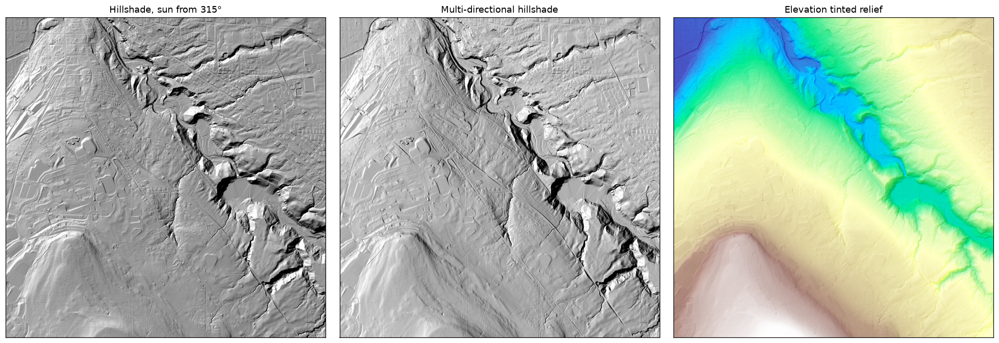

In [4]:
hs315 = rs.lidar.hillshade(dem, azimuth=315, altitude=45)  # classic north-west light
hs_multi = sum(rs.lidar.hillshade(dem, azimuth=a, altitude=45) for a in (225, 270, 315, 360)) / 4  # four azimuths
ls = LightSource(azdeg=315, altdeg=45)  # light source for the tinted relief
# elevation colours shaded by relief
tinted = ls.shade(np.nan_to_num(dem.values, nan=float(dem.mean())), cmap=plt.cm.terrain, blend_mode="soft",
                  vert_exag=2, dx=1, dy=1)  # elevation colours shaded by relief

fig, axes = plt.subplots(1, 3, figsize=(18, 6))  # three panels
rs.viz.plot_raster(hs315, ax=axes[0], cmap="gray", colorbar=False, title="Hillshade, sun from 315°")  # one light
rs.viz.plot_raster(hs_multi, ax=axes[1], cmap="gray", colorbar=False, title="Multi-directional hillshade")  # four lights
axes[2].imshow(tinted); axes[2].set_title("Elevation tinted relief")  # colour relief
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

The valley of Six Mile Creek runs from the south-east to the north-west, with a reservoir pond in its middle reach and steep, gullied valley walls. South Hill rises to the south-west, and fields, roads, quarries and housing are visible on the plateaus. The 1 m DEM shows field boundaries, road cuts and individual driveways.


## Local terrain derivatives

All six local derivatives come from the same 1 m DEM. TPI uses a 51-cell (51 m) window to capture valley and ridge positions rather than micro-relief.


six derivatives of a 9 million-cell DEM in 1.0 s


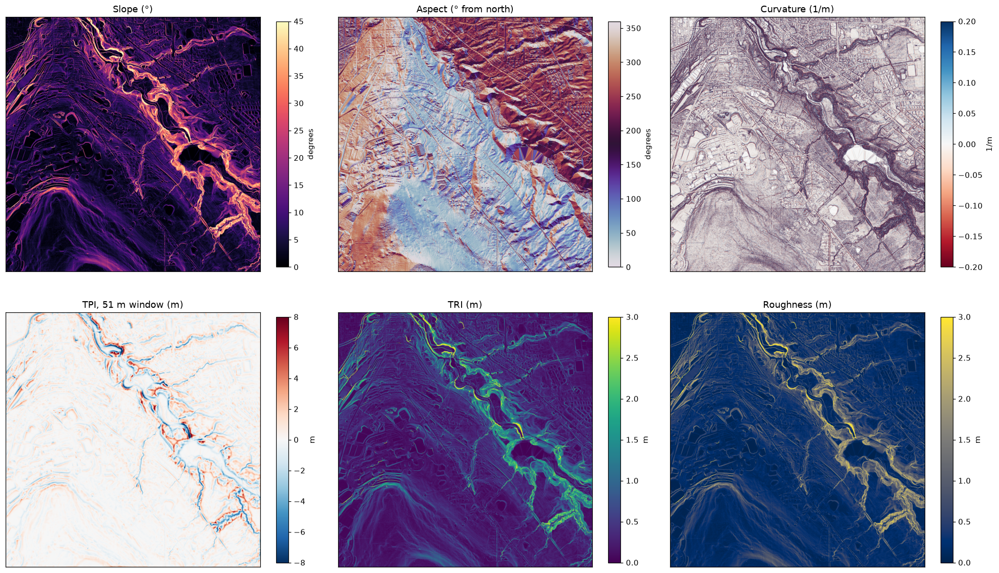

In [5]:
t0 = time.perf_counter()  # start the timer
deriv = {"Slope (°)": (rs.lidar.slope(dem), "magma", (0, 45)),  # steepness
         "Aspect (° from north)": (rs.lidar.aspect(dem), "twilight", (0, 360)),  # exposure
         "Curvature (1/m)": (rs.lidar.curvature(dem), "RdBu", (-0.2, 0.2)),  # convex vs concave
         "TPI, 51 m window (m)": (rs.lidar.tpi(dem, window=51), "RdBu_r", (-8, 8)),  # topographic position
         "TRI (m)": (rs.lidar.tri(dem), "viridis", (0, 3)),  # ruggedness
         "Roughness (m)": (rs.lidar.roughness(dem), "cividis", (0, 3))}  # local relief
print(f"six derivatives of a {dem.size / 1e6:.0f} million-cell DEM in {time.perf_counter() - t0:.1f} s")  # timing

fig, axes = plt.subplots(2, 3, figsize=(18, 11))  # six panels
for ax, (title, (img, cmap, (lo, hi))) in zip(axes.ravel(), deriv.items()):  # each derivative
    rs.viz.plot_raster(img, ax=ax, cmap=cmap, vmin=lo, vmax=hi, title=title)  # map
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

In [6]:
stats = pd.DataFrame({k: pd.Series(v[0].values.ravel()).describe(percentiles=[0.05, 0.5, 0.95])  # summary per layer
                      for k, v in deriv.items()}).T[["mean", "5%", "50%", "95%", "max"]]
stats.round(3)  # show it

,mean,5%,50%,95%,max
Slope (°),8.809,0.939,5.756,29.350,84.150
Aspect (° from north),176.759,12.925,198.750,345.957,359.998
Curvature (1/m),0.000,-0.297,0.000,0.289,29.183
"TPI, 51 m window (m)",0.000,-1.502,0.013,1.421,10.961
TRI (m),0.439,0.061,0.275,1.456,31.585
Roughness (m),0.440,0.057,0.274,1.470,24.852


Slopes above 35 to 40° line the creek gorge and its side gullies; the plateaus are mostly below 5°. Curvature and roughness highlight sharp breaks such as road cuts, stream banks and building pads, while TPI with a 51 m window separates the valley floor (negative) from spurs and the valley rim (positive).

**Illumination** gives the cosine of the incidence angle of sunlight for a given sun position, the quantity used in topographic correction of optical images. `rs.lidar.sun_positions` gives the sun's azimuth and elevation for a latitude, day and hour.


     day  hour     azimuth  elevation
0  172.0  10.0  117.842664  58.751510
1  355.0  10.0  151.053333  18.565486


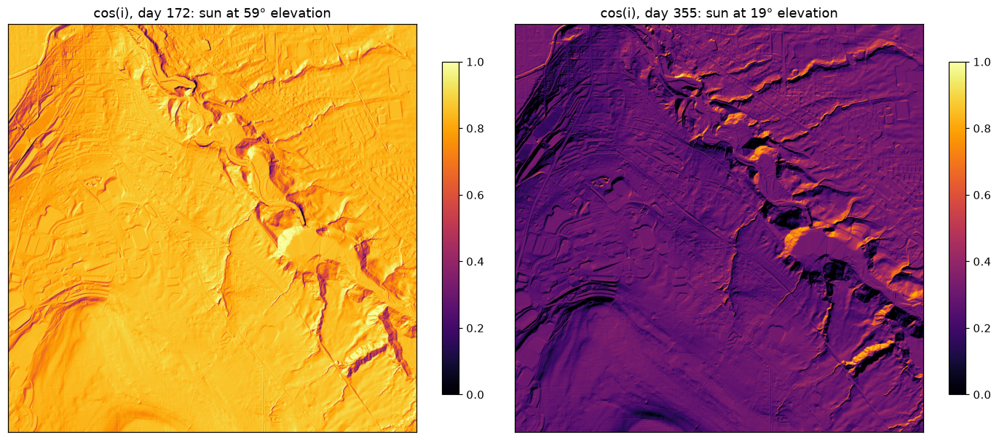

In [7]:
sun = rs.lidar.sun_positions(42.43, days=[172, 355], hours=[10])  # 10:00 solar time on 21 June and 21 December
print(sun)  # sun azimuth and elevation
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))  # two panels
for ax, (_, s) in zip(axes, sun.iterrows()):  # each sun position
    cos_i = rs.lidar.illumination(dem2, s["azimuth"], s["elevation"])  # cos of the incidence angle
    rs.viz.plot_raster(cos_i, ax=ax, cmap="inferno", vmin=0, vmax=1,  # map
                       title=f"cos(i), day {int(s['day'])}: sun at {s['elevation']:.0f}° elevation")
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

## Scale: window size and DEM resolution

Terrain variables are not unique properties of a place: they depend on the DEM resolution and on the window size. The left panel shows TPI at three window sizes; the table and right panel show how the slope distribution changes when the 1 m DEM is aggregated to coarser cells, as it would be for a 10 m or 30 m national DEM.


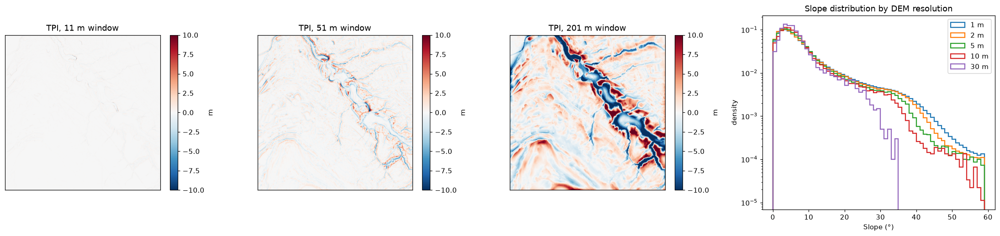

,mean slope (°),95th percentile (°),share > 30° (%)
1 m,8.81,29.35,4.71
2 m,8.46,28.06,4.15
5 m,7.99,25.43,3.07
10 m,7.57,23.15,2.11
30 m,6.72,18.55,0.17


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), gridspec_kw={"width_ratios": [1, 1, 1, 1.2]})  # four panels
for ax, w in zip(axes[:3], (11, 51, 201)):  # three TPI windows (cells = m)
    rs.viz.plot_raster(rs.lidar.tpi(dem2, window=max(3, w // 2) | 1), ax=ax, cmap="RdBu_r", vmin=-10, vmax=10,  # TPI map
                       title=f"TPI, {w} m window")
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
rows = {}  # one row per resolution
for res in (1, 2, 5, 10, 30):  # aggregation factors (m)
    d = dem if res == 1 else dem.coarsen(x=res, y=res, boundary="trim").mean().rio.write_crs(dem.rio.crs)  # aggregate
    s = rs.lidar.slope(d).values.ravel()  # slope values
    s = s[np.isfinite(s)]  # drop empty cells
    rows[f"{res} m"] = {"mean slope (°)": s.mean(), "95th percentile (°)": np.percentile(s, 95),  # statistics
                        "share > 30° (%)": 100 * np.mean(s > 30)}
    axes[3].hist(s, bins=np.arange(0, 60, 1), histtype="step", density=True, lw=1.5, label=f"{res} m")  # distribution
axes[3].set(xlabel="Slope (°)", ylabel="density", yscale="log", title="Slope distribution by DEM resolution")  # labels
axes[3].legend(); plt.tight_layout(); plt.show()  # draw
pd.DataFrame(rows).T.round(2)  # show the table

Coarser DEMs average steep gorge walls with the flats beside them, so the steepest slopes disappear: the share of terrain steeper than 30° falls sharply between 1 m and 30 m. Models fitted with slope from one resolution should not be applied with slope from another.


## Landforms with geomorphons

`rs.lidar.geomorphons` looks out to `search` cells in eight directions. With a 2 m DEM, a search of 50 cells (100 m) matches the width of the valley side slopes and gullies.


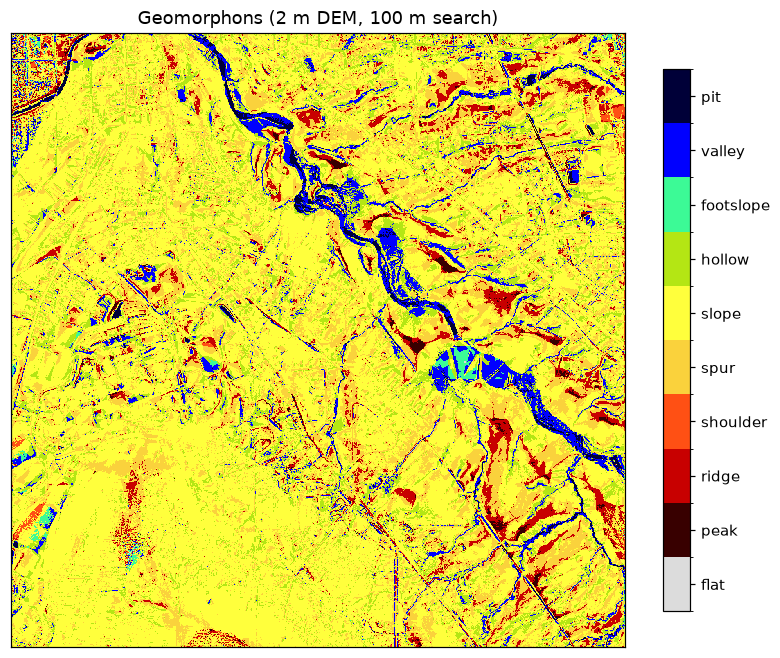

,slope,spur,hollow,ridge,valley,pit,peak,footslope,shoulder,flat
share,0.541,0.203,0.126,0.055,0.049,0.011,0.007,0.004,0.004,0.0


In [9]:
geo = rs.lidar.geomorphons(dem2, search=50, flat_deg=1.0)  # landform classes on the 2 m DEM
gcol = {1: "#dcdcdc", 2: "#380000", 3: "#c80000", 4: "#ff5014", 5: "#fad23c", 6: "#ffff3c", 7: "#b4e614",
        8: "#3cfa96", 9: "#0000ff", 10: "#000038"}  # standard geomorphon colours
fig, ax = plt.subplots(figsize=(9, 8))  # one panel
rs.viz.plot_raster(geo.where(geo > 0), ax=ax, title="Geomorphons (2 m DEM, 100 m search)",  # landform map
                   categorical={k: (v, gcol[k]) for k, v in GEOMORPHON_CLASSES.items()})
ax.set_xticks([]); ax.set_yticks([]); plt.show()  # draw
pd.Series(geo.values.ravel()).map(GEOMORPHON_CLASSES).value_counts(normalize=True).round(3).to_frame("share").T  # shares

## Depression filling and road embankments

`rs.lidar.fill_depressions` raises every pit to its spill point. The **fill depth** (filled minus original DEM) shows where water would pond if it could not escape. In a LiDAR DEM most large "depressions" are not real: they sit upstream of road embankments, driveways and dams, where the water actually passes through a culvert that the laser cannot see.


filled in 10.0 s | raised cells: 3.0% | largest fill 7.2 m | filled volume 255 thousand m³


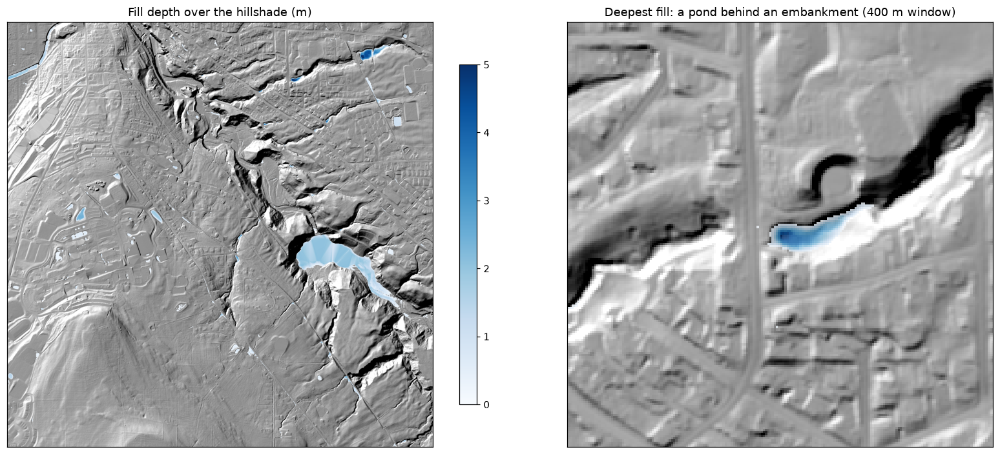

In [10]:
t0 = time.perf_counter()  # start the timer
filled = rs.lidar.fill_depressions(dem2)  # priority-flood filling on the 2 m DEM
fill_depth = (filled - dem2).where(lambda d: d > 0.05)  # where the DEM was raised by more than 5 cm
# summary line
print(f"filled in {time.perf_counter() - t0:.1f} s | raised cells: {float(fill_depth.notnull().mean()):.1%} | "
      f"largest fill {float(fill_depth.max()):.1f} m | filled volume {float(fill_depth.sum() * 4) / 1e3:,.0f} thousand m³")  # summary

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))  # two panels
rs.viz.plot_raster(rs.lidar.hillshade(dem2), ax=axes[0], cmap="gray", colorbar=False,  # relief background
                   title="Fill depth over the hillshade (m)")
fd_plot = fill_depth.where(fill_depth > 0.2)  # fills deeper than 20 cm
im = axes[0].imshow(fd_plot.values, cmap="Blues", vmin=0, vmax=5,  # fill depth overlay
                    extent=[float(dem2.x.min()), float(dem2.x.max()), float(dem2.y.min()), float(dem2.y.max())])
plt.colorbar(im, ax=axes[0], shrink=0.8)  # colour bar
big = fill_depth.where(fill_depth > 1).notnull()  # fills deeper than 1 m
rr, cc = np.unravel_index(np.nanargmax(np.where(big, fill_depth.values, np.nan)), big.shape)  # deepest fill
win = dict(y=slice(max(rr - 100, 0), rr + 100), x=slice(max(cc - 100, 0), cc + 100))  # 400 m window around it
rs.viz.plot_raster(rs.lidar.hillshade(dem2).isel(win), ax=axes[1], cmap="gray", colorbar=False,  # zoomed relief
                   title="Deepest fill: a pond behind an embankment (400 m window)")
sub = fill_depth.isel(win)  # zoomed fill depth
axes[1].imshow(sub.where(sub > 0.2).values, cmap="Blues", vmin=0, vmax=float(sub.max()), alpha=0.8,  # overlay
               extent=[float(sub.x.min()), float(sub.x.max()), float(sub.y.min()), float(sub.y.max())])
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

The deepest fills sit upstream of road embankments and of the dam on Six Mile Creek. Filling them gives a DEM in which water always reaches the edge, but it also creates large artificial lakes. Hydrological DEM conditioning therefore "burns" culverts and bridges into the DEM (lowering the embankment along the culvert) before filling; national products such as the USGS 3DEP hydro-flattened DEMs and the NHDPlus HR use such conditioning.


## Flow direction, flow accumulation and streams

`rs.lidar.flow_direction` gives the D8 receiver of every cell (0 = north, clockwise to 7 = north-west) and `rs.lidar.flow_accumulation` the number of upslope cells. Cells draining more than 10 ha (25,000 cells of 4 m²) are taken as streams.


flow direction and accumulation in 1.4 s | max 1,722,520 cells = 6.9 km² draining through one cell


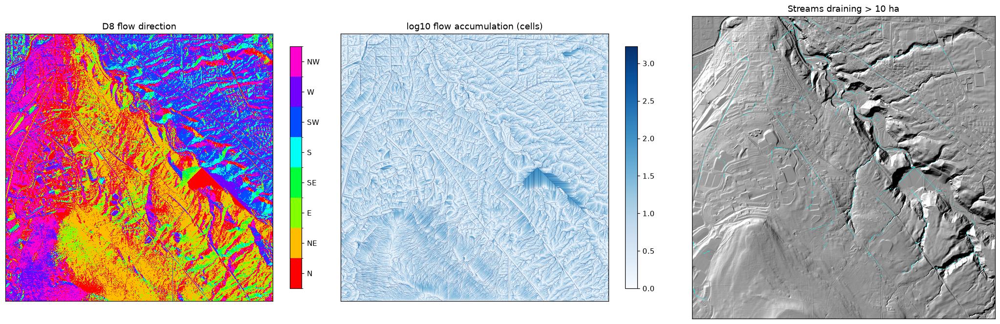

In [11]:
t0 = time.perf_counter()  # start the timer
fdir = rs.lidar.flow_direction(filled)  # D8 directions
acc = rs.lidar.flow_accumulation(filled, filled=True)  # upslope cells
# summary line
print(f"flow direction and accumulation in {time.perf_counter() - t0:.1f} s | max {float(acc.max()):,.0f} cells "
      f"= {float(acc.max()) * 4 / 1e6:.1f} km² draining through one cell")  # largest catchment in the window
STREAM_CELLS = 25_000  # 10 ha at 2 m cells
streams = acc >= STREAM_CELLS  # stream network

fig, axes = plt.subplots(1, 3, figsize=(19, 6))  # three panels
rs.viz.plot_raster(fdir.where(fdir >= 0), ax=axes[0], title="D8 flow direction",  # directions
                   categorical={i: (n, plt.cm.hsv(i / 8)) for i, n in enumerate(["N", "NE", "E", "SE", "S", "SW", "W", "NW"])})
rs.viz.plot_raster(np.log10(acc), ax=axes[1], cmap="Blues", title="log10 flow accumulation (cells)")  # accumulation
rs.viz.plot_raster(rs.lidar.hillshade(dem2), ax=axes[2], cmap="gray", colorbar=False,  # relief background
                   title="Streams draining > 10 ha")
ext = [float(dem2.x.min()), float(dem2.x.max()), float(dem2.y.min()), float(dem2.y.max())]  # map extent
axes[2].imshow(np.where(streams, 1, np.nan), cmap="cool", extent=ext, interpolation="nearest")  # streams
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

Six Mile Creek collects most of the flow, joined by side streams from the gullies on both valley walls. On the flat fields and filled ponds D8 routes water along parallel straight lines (the striped texture of the accumulation map), a known artefact of single-direction routing on flats; multiple-flow-direction methods spread the flow more realistically on hillslopes.


## Topographic Wetness Index

`rs.lidar.twi` combines the specific catchment area with the local slope. Valley floors, hollows and the edges of flat fields have high TWI; ridges and steep walls have low TWI.


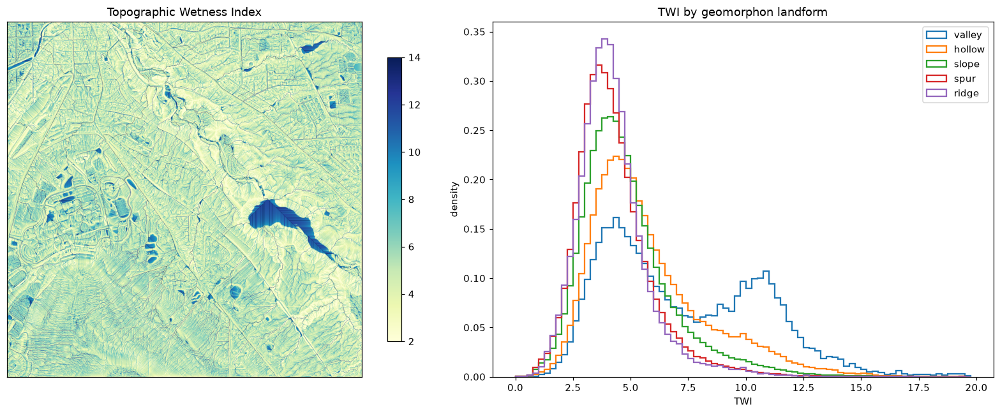

In [12]:
twi = rs.lidar.twi(filled)  # ln(a / tan β)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))  # two panels
rs.viz.plot_raster(twi, ax=axes[0], cmap="YlGnBu", vmin=2, vmax=14, title="Topographic Wetness Index")  # map
axes[0].set_xticks([]); axes[0].set_yticks([])  # no ticks
for name, cls in (("valley", 9), ("hollow", 7), ("slope", 6), ("spur", 5), ("ridge", 3)):  # landforms
    v = twi.values[geo.values == cls]  # TWI of that landform
    axes[1].hist(v[np.isfinite(v)], bins=np.arange(0, 20, 0.25), histtype="step", density=True, lw=1.5, label=name)  # histogram
axes[1].set(xlabel="TWI", ylabel="density", title="TWI by geomorphon landform"); axes[1].legend()  # labels
plt.tight_layout(); plt.show()  # draw

## Height Above Nearest Drainage and flood extent

`rs.lidar.hand` follows the D8 path from every cell to the first stream cell and subtracts the stream's elevation. `rs.lidar.inundation` on the HAND raster then gives the area below a water stage measured above the channel, connected to the stream network. This is the basis of the NOAA National Water Model's continental flood inundation maps; it ignores hydraulics (velocity, backwater, embankments), so it is a first screening, not a flood model.


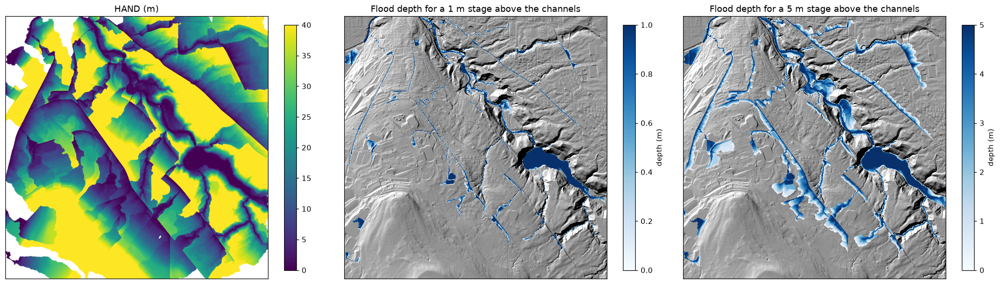

,flooded area (ha),mean depth (m)
1 m stage,46.08,0.74
3 m stage,84.96,1.94
5 m stage,126.02,2.98


In [13]:
hand = rs.lidar.hand(filled, threshold=STREAM_CELLS, filled=True)  # height above the nearest stream (m)
stream_xy = [(float(dem2.x[c]), float(dem2.y[r])) for r, c in zip(*np.nonzero(streams.values))][::50]  # seed points on streams
floods = {stage: rs.lidar.inundation(hand, stage, seeds=stream_xy) for stage in (1, 3, 5)}  # three stages (m)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))  # three panels
rs.viz.plot_raster(hand, ax=axes[0], cmap="viridis", vmin=0, vmax=40, title="HAND (m)")  # HAND map
for ax, stage in zip(axes[1:], (1, 5)):  # two stages
    rs.viz.plot_raster(rs.lidar.hillshade(dem2), ax=ax, cmap="gray", colorbar=False,  # relief background
                       title=f"Flood depth for a {stage} m stage above the channels")
    d = floods[stage]["depth"]  # depth raster
    im = ax.imshow(d.values, cmap="Blues", vmin=0, vmax=stage, extent=ext, interpolation="nearest")  # depth overlay
    plt.colorbar(im, ax=ax, shrink=0.8, label="depth (m)")  # colour bar
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw
pd.DataFrame({f"{s} m stage": {"flooded area (ha)": float(f["extent"].sum()) * 4 / 1e4,  # area per stage
                               "mean depth (m)": float(f["depth"].mean())} for s, f in floods.items()}).T.round(2)

HAND is low along Six Mile Creek, its tributaries and the reservoir, and rises quickly up the valley walls. White areas have no HAND value: they drain off the edge of this 3 km window before reaching a stream cell, which is why HAND and flow accumulation should be computed on a DEM that covers whole catchments. Some straight flooded lines follow roadside ditches and an old railway grade, which the 1 m DEM resolves as channels. The 1 m stage already fills the reservoir and the creek bed; the 5 m stage spreads onto the low terraces of the valley floor.


## A cross-valley profile

Sampling the DEM along a line across the valley shows the shape of the gorge, the reservoir surface and the plateaus on both sides. `xarray`'s `interp` samples the DEM at points spaced 1 m apart along the line.


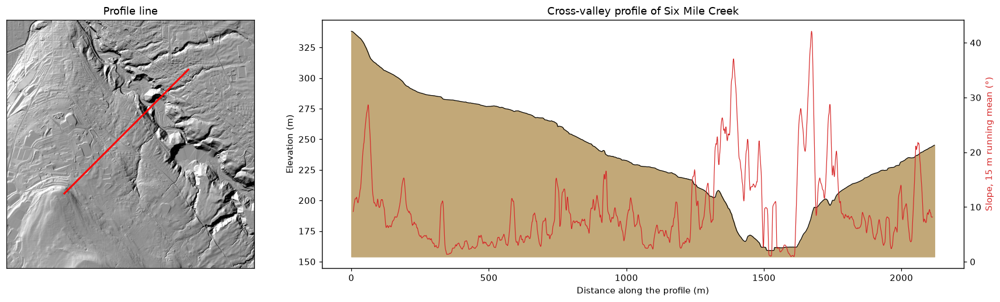

In [14]:
x0, y0, x1, y1 = 377200, 4697400, 378700, 4698900  # from the south-west plateau to the north-east plateau
n = int(np.hypot(x1 - x0, y1 - y0))  # one sample per metre
xs, ys = np.linspace(x0, x1, n), np.linspace(y0, y1, n)  # sample positions
prof = dem.interp(x=xr.DataArray(xs, dims="d"), y=xr.DataArray(ys, dims="d"))  # bilinear samples of the DEM
slp = rs.lidar.slope(dem).interp(x=xr.DataArray(xs, dims="d"), y=xr.DataArray(ys, dims="d"))  # slope along the line

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 2.2]})  # two panels
rs.viz.plot_raster(rs.lidar.hillshade(dem2), ax=axes[0], cmap="gray", colorbar=False, title="Profile line")  # map
axes[0].plot([x0, x1], [y0, y1], "r-", lw=2); axes[0].set_xticks([]); axes[0].set_yticks([])  # the line
axes[1].fill_between(np.arange(n), prof, float(prof.min()) - 5, color="#c2a878")  # terrain profile
axes[1].plot(np.arange(n), prof, "k-", lw=0.8)  # outline
ax2 = axes[1].twinx(); ax2.plot(np.arange(n), slp.rolling(d=15, center=True).mean(), color="C3", lw=0.8)  # 15 m mean slope
ax2.set_ylabel("Slope, 15 m running mean (°)", color="C3")  # slope label
axes[1].set(xlabel="Distance along the profile (m)", ylabel="Elevation (m)", title="Cross-valley profile of Six Mile Creek")  # labels
plt.tight_layout(); plt.show()  # draw

## Exporting the products

The DEM and the derived layers are written as Cloud-Optimized GeoTIFFs with `rs.write`.


In [15]:
# products to save
layers = {"ithaca_dem_1m": dem, "ithaca_slope_1m": deriv["Slope (°)"][0], "ithaca_tpi51_1m": deriv["TPI, 51 m window (m)"][0],
          "ithaca_geomorphons_2m": geo.astype("uint8"), "ithaca_flowacc_2m": acc, "ithaca_twi_2m": twi,
          "ithaca_hand_2m": hand, "ithaca_flood_depth_3m_stage": floods[3]["depth"]}  # products to save
for name, da in layers.items():  # each product
    rs.write(da if da.dtype == "uint8" else da.astype("float32"), OUT / f"{name}.tif")  # COG
    print(f"{name + '.tif':32s} {(OUT / f'{name}.tif').stat().st_size / 1e6:6.1f} MB")  # name and size

ithaca_dem_1m.tif                  35.8 MB


ithaca_slope_1m.tif                42.6 MB


ithaca_tpi51_1m.tif                36.7 MB
ithaca_geomorphons_2m.tif           0.6 MB


ithaca_flowacc_2m.tif               4.8 MB
ithaca_twi_2m.tif                  10.2 MB


ithaca_hand_2m.tif                  9.0 MB
ithaca_flood_depth_3m_stage.tif     0.7 MB


## Summary and exercises

**Key points**

- A seamless DEM from several tiles needs grids aligned to the same origin; tile-by-tile interpolation can leave small seams, which buffered tiles avoid.
- Slope, aspect, curvature, TPI, TRI and roughness are local derivatives; their values depend on the DEM resolution and the window size, so models must use the same scale for fitting and prediction.
- Geomorphons classify landforms from line-of-sight patterns and adapt to the scale of the landform through the search distance.
- In 1 m LiDAR DEMs, road embankments and dams create large artificial depressions; condition the DEM (burn culverts, flatten water) before routing flow.
- D8 flow accumulation gives stream networks; TWI marks wet areas; HAND relative to the stream network gives a quick first estimate of flood extent for a given stage.

**`geolattice.rsense` functions used:** `rs.lidar.las_info`, `rs.lidar.read_las` (with `fields`), `rs.lidar.dem`, `rs.lidar.merge_rasters`, `rs.lidar.hillshade`, `rs.lidar.slope`, `rs.lidar.aspect`, `rs.lidar.curvature`, `rs.lidar.tpi`, `rs.lidar.tri`, `rs.lidar.roughness`, `rs.lidar.illumination`, `rs.lidar.sun_positions`, `rs.lidar.geomorphons`, `rs.lidar.fill_depressions`, `rs.lidar.flow_direction`, `rs.lidar.flow_accumulation`, `rs.lidar.twi`, `rs.lidar.hand`, `rs.lidar.inundation`, `rs.write`, `rs.viz.plot_raster`.

**Exercises**

1. Build the DEM from all ten Ithaca tiles at 2 m. Where do the tile seams show in a hillshade?
2. Change the stream threshold to 1 ha and 100 ha. How does the drainage density (stream length per km²) change?
3. Compute geomorphons with search distances of 10, 50 and 150 cells. Which landforms appear or disappear?
4. Lower the DEM by 3 m along a short line across the road embankment with the deepest fill (a "burned" culvert) and fill again. How much of the artificial pond disappears?
5. Compare TWI computed on the 2 m and on a 10 m version of the DEM. Which places change most?
